 ENGG1003 Digital Literacy and Computational Thinking - P 

Course Project 

 I declare that the project here submitted is original 
 except for source material explicitly acknowledged, 
 and that the same or closely related material has not been 
 previously submitted for another course. 
 I also acknowledge that I am aware of University policy and 
 regulations on honesty in academic work, and of the disciplinary 
 guidelines and procedures applicable to breaches of such 
 policy and regulations, as contained in the website. 
 
 University Guideline on Academic Honesty: 

   https://www.cuhk.edu.hk/policy/academichonesty/ 

 Student Name  : CAI Xinyi
 Student ID: 1155256903
 Class/Section : ENGG1003SA
 Date: 12/4/2026

Please: click the URL and download the clean dataset
URL:https://www.kaggle.com/datasets/arthurchongg/imdb-top-1000-movies
install scipy library
open Jupyter notebook and drag imdb_clean.csv to the file
click "Restart Kernel and run all cells"
The dataset documented seven attributes of the movies: time of release, director, runtime, gross, rating, genre, and Metascore (rating by professional critics).      
In this project, after data summarization, I explore the correlations between movie runtime, gross (box office revenue) and IMDb ratings; 
screen out frequently appearing genres; and analyze the eras where popular movies are concentrated.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from sklearn.cluster import KMeans

In [2]:
pd.set_option('display.max_columns', None)  #display all columns
pd.set_option('display.max_rows', None)  #display all rows
pd.set_option('display.width', None)       

In [3]:
df = pd.read_csv("imdb_clean.csv")
#Our original dataset df list out every genre of every movie independently as an independent row. For example, if A is both "action" and "drama", then there are two rows of A.
#This will affect our calculations, so we need another dataframe that merges the rows that are the same.

#data cleansing

df = df.dropna(
    subset=['runtime', 'gross(M)', 'metascore', 'rating', 'director', 'release_year']
)  #remove all the movies with missing data
df = df[df["gross(M)"] > 0]          #we do not consider movies without a ticket house
df = df[df["metascore"] > 0]      # we only consider movies with a Metascore

df_=df.drop_duplicates(subset=['title'], keep='first')   #merge rows indicating one movie

print(f"the number of movies after cleansed: {df_.shape[0]}") #Inform the user of the number of movies left after cleansed

the number of movies after cleansed: 732


In [4]:
#data summarization
print("--- Basic Statistics ---")

#summarize statistics of the movies
print(df_[['rating', 'runtime', 'gross(M)','metascore','release_year']].describe())  
print("\n=== Pivot Table: Year vs Avg Rating, Gross, Runtime ===")
pivot = df.pivot_table(
    index='release_year',
    values=['rating', 'gross(M)', 'runtime'],
    aggfunc='mean'
)
print(pivot.round(2))  

--- Basic Statistics ---
           rating     runtime    gross(M)   metascore  release_year
count  732.000000  732.000000  732.000000  732.000000    732.000000
mean     7.953962  124.166667   78.473497   78.296448   1994.349727
std      0.287350   27.066157  121.122981   12.003800     20.633220
min      7.600000   64.000000    0.010000   28.000000   1925.000000
25%      7.700000  104.000000    5.000000   71.000000   1984.000000
50%      7.900000  120.000000   31.900000   79.000000   2000.000000
75%      8.100000  137.000000  101.437500   87.000000   2010.000000
max      9.300000  238.000000  936.660000  100.000000   2022.000000

=== Pivot Table: Year vs Avg Rating, Gross, Runtime ===
              gross(M)  rating  runtime
release_year                           
1925              0.05    7.90    66.00
1927              0.89    8.20   123.50
1928              0.02    8.20   114.00
1930              3.27    8.10   152.00
1931              0.02    8.50    87.00
1932              0.63    

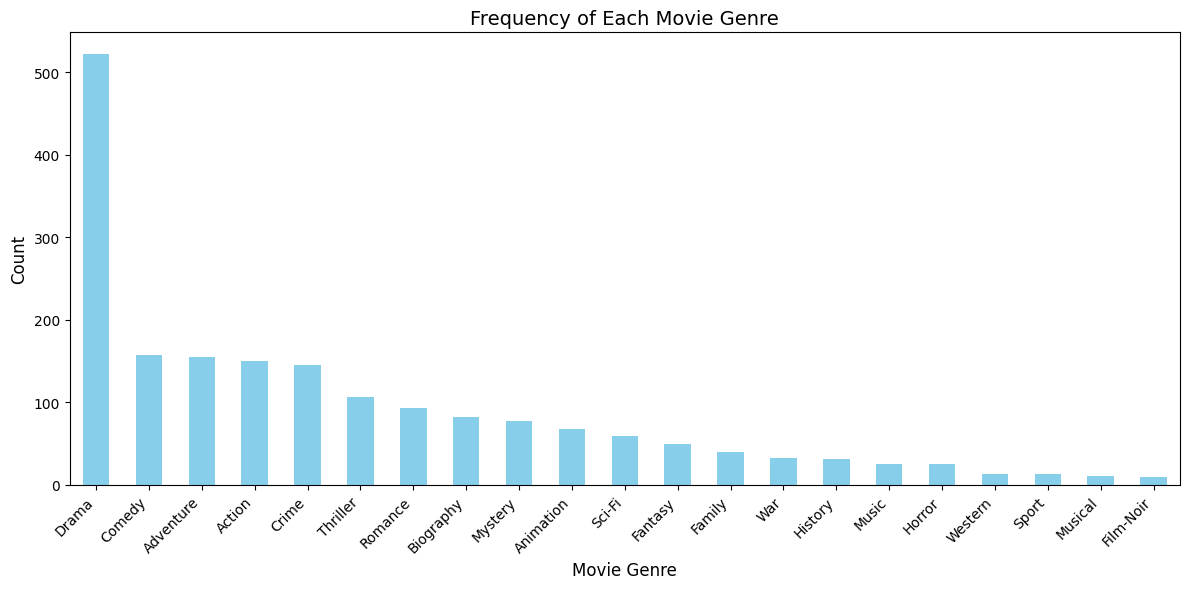

In [5]:
#data visualization

#plot a graph, showing the frequencies of every genre

#count types of genre
genre_count = df['genre'].value_counts()

plt.figure(figsize=(12, 6))
genre_count.plot(kind='bar', color='skyblue')

# add a title and x labels
plt.title('Frequency of Each Movie Genre', fontsize=14)
plt.xlabel('Movie Genre', fontsize=12)
plt.ylabel('Count', fontsize=12)

# make sure the x labels don't overlap
plt.xticks(rotation=45, ha='right')

# adjust the layout
plt.tight_layout()

#plot the chart
plt.show()

#Observartion:
#Drama is the most popular genre. Comedy, adventure, action and crime are popular genres as well.

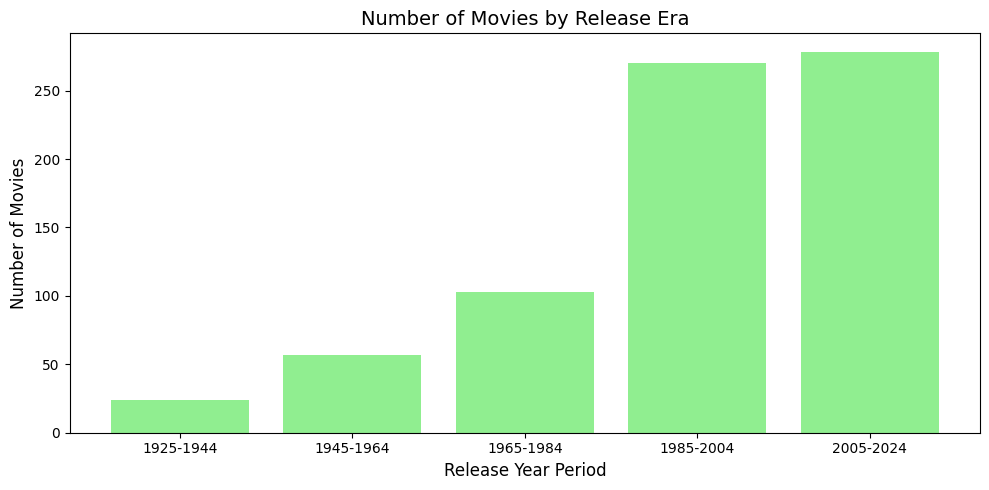

In [6]:
#study in what eras the movies are concentrated
bins = [1925, 1945, 1965, 1985, 2005, 2026]
labels = ['1925-1944', '1945-1964', '1965-1984', '1985-2004', '2005-2024']

# identify the era
df=df_.copy()
df_['era'] = pd.cut(df_['release_year'], bins=bins, labels=labels, right=False)
era_count = df_['era'].value_counts().sort_index()


plt.figure(figsize=(10, 5))
bars = plt.bar(era_count.index, era_count.values, color='lightgreen')

# add a title and labels
plt.title('Number of Movies by Release Era', fontsize=14)
plt.xlabel('Release Year Period', fontsize=12)
plt.ylabel('Number of Movies', fontsize=12)

#plot a chart
plt.tight_layout()
plt.show()

#Observation: The count grows steadily over time, with the fewest films in 1925–1944 and the most in 1985–2004 and 2005–2024.
#This indicates a significant expansion of film production in recent decades.


Text(0, 0.5, 'Gross(M)')

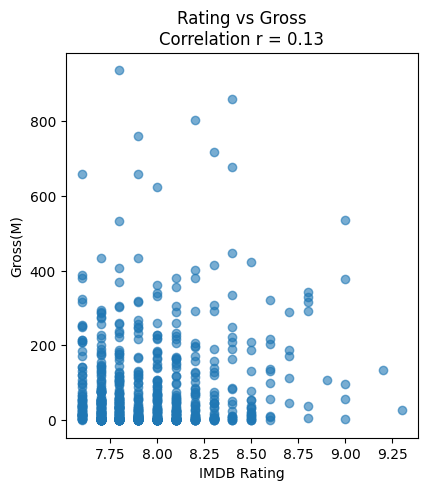

In [7]:
# --------------------- 1. Rating vs Gross ---------------------
slope1, intercept1, r1, p1, std_err1 = stats.linregress(df_['rating'], df_['gross(M)'])

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.scatter(df_['rating'], df_['gross(M)'], alpha=0.6)
plt.title(f'Rating vs Gross\nCorrelation r = {r1:.2f}')
plt.xlabel('IMDB Rating')
plt.ylabel('Gross(M)')

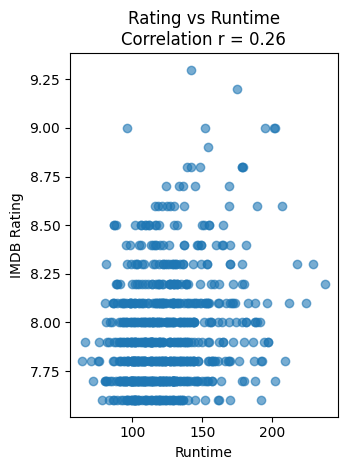

In [8]:
# --------------------- 2. Rating vs Runtime ---------------------
#study whether a linear relationship exists between rating and runtime
slope2, intercept2, r2, p2, std_err2 = stats.linregress(df_['runtime'],df_['rating'])

plt.subplot(1,2,2)
plt.scatter(df_['runtime'],df_['rating'],alpha=0.6)

#add a title and labels
plt.title(f'Rating vs Runtime\nCorrelation r = {r2:.2f}')
plt.xlabel('Runtime')
plt.ylabel('IMDB Rating')

#plot the chart
plt.tight_layout()
plt.show()

In [9]:
#interpret correlation
def interpret_correlation(r):
    if abs(r) >= 0.7:
        return "strong correlation"
    elif abs(r) >= 0.4:
        return "moderate correlation"
    elif abs(r) >= 0.1:
        return "weak correlation"
    else:
        return "almost no correlation"


result_gross = interpret_correlation(r1)
result_runtime = interpret_correlation(r2)

# give the results
print("--- Data Modelling Conclusion ---")
print(f"Between Rating and Gross: r = {r1:.2f}, which is a {result_gross}.")
print(f"Between Rating and Runtime: r = {r2:.2f}, which is a {result_runtime}.")

#Observation: Strong correlation doesn't exist in between rating and gross or rating and runtime

--- Data Modelling Conclusion ---
Between Rating and Gross: r = 0.13, which is a weak correlation.
Between Rating and Runtime: r = 0.26, which is a weak correlation.


3.1 Summary
This project focuses on a movie dataset, aiming to explore the distribution of movie release periods and linear relationships between core movie indicators. First, the dataset was cleaned. Then, a barplot was plotted to indicate what genre is the most common among popular movies. Then I categorized the movies into five distinct release eras based on release year: 1925-1944, 1945-1964, 1965-1984, 1985-2004, and 2005-2025, followed by generating a bar chart to visualize the number of movies in each era. Subsequently, basic data modelling was conducted to examine potential linear correlations between IMDB rating and box office gross (in millions), as well as between IMDB rating and movie runtime, using correlation coefficient calculation and scatter plots with linear fitting lines. 

The visual analysis of the release era bar chart reveals a clear upward trend in movie production volume over time, with the earliest era (1925-1944) having the fewest movie entries, and the two latest eras (1985-2004, 2005-2025) accounting for the majority of the dataset. The linear modelling results further quantify the correlation strength between the selected variables, providing clear statistical evidence for the relationship analysis.

3.2 Conclusion
Firstly, drama is the most popular genre among all movies. A large number of popular movies fall into this category. Comedy, adventure and crime are popular genres as well.

Secondly, the number of movies in the dataset increase with time. The early 20th-century film productions are far less represented in the dataset.

Thirdly, the linear correlation modelling shows a weak positive linear correlation between movie rating and box office gross, meaning higher-rated movies tend to have slightly higher box office revenue, but the relationship is not strong. And there is almost no linear correlation between movie rating and runtime, proving that a movie’s runtime length has little to no linear impact on its audience rating. These conclusions confirm that linear relationships do not dominate between rating and the other two variables, and other factors may play more importan roles in determining movie gross and rating.

3.3 Reflection

Throughout this project, I have gained practical hands-on experience in data processing, visualisation, and basic data modelling, which has strengthened my understanding of Python data analysis tools. I also revised the slides of this course and found them very useful. Initially, I made minor mistakes in setting year grouping bins and encountered coding errors such as missing library imports and undefined variables, which taught me the importance of careful code checking and logical variable definition in data analysis. 


3.4 Citations and References

Online Sources

1. Pandas Development Team. “Pandas Documentation.” Accessed March 23, 2026. https://pandas.pydata.org/docs/.

2. NumPy Developers. “NumPy Documentation.” Accessed March 23, 2026. https://numpy.org/doc/.

Offline/Academic Sources

1. Field, Andy. Discovering Statistics Using Python. Los Angeles: SAGE Publications, 2020.

2. McKinney, Wes. Python for Data Analysis: Data Wrangling with Pandas, NumPy, and IPython. Sebastopol: O’Reilly Media, 2018.